# Supplementary Figure S2a. Number of gene modules identified by Hotspot and WGCNA

Number of co-expression modules detected by Hotspot (minimum module size 10, 30 or 50 genes) and by WGCNA in GTEx brain cortex, GTEx whole blood and nine ROSMAP expression contexts (six snRNA-seq cell types and three bulk brain regions). Counts are the number of modules in each saved module list; no statistical test is involved.

Input: `data/Figure_S2a_module_counts.rds`.

In [1]:
library(ggplot2)
library(patchwork)
dat <- readRDS("data/Figure_S2a_module_counts.rds")
dat

cohort,context,method,min_module_size,n_modules,group
<chr>,<chr>,<chr>,<int>,<int>,<chr>
ROSMAP,Mic,Hotspot,10,264,Hotspot (minGene = 10)
ROSMAP,Mic,Hotspot,30,71,Hotspot (minGene = 30)
ROSMAP,Mic,Hotspot,50,47,Hotspot (minGene = 50)
ROSMAP,Mic,WGCNA,NA,102,WGCNA
ROSMAP,Exc,Hotspot,10,504,Hotspot (minGene = 10)
ROSMAP,Exc,Hotspot,30,144,Hotspot (minGene = 30)
ROSMAP,Exc,Hotspot,50,74,Hotspot (minGene = 50)
ROSMAP,Exc,WGCNA,NA,158,WGCNA
ROSMAP,Inh,Hotspot,10,476,Hotspot (minGene = 10)


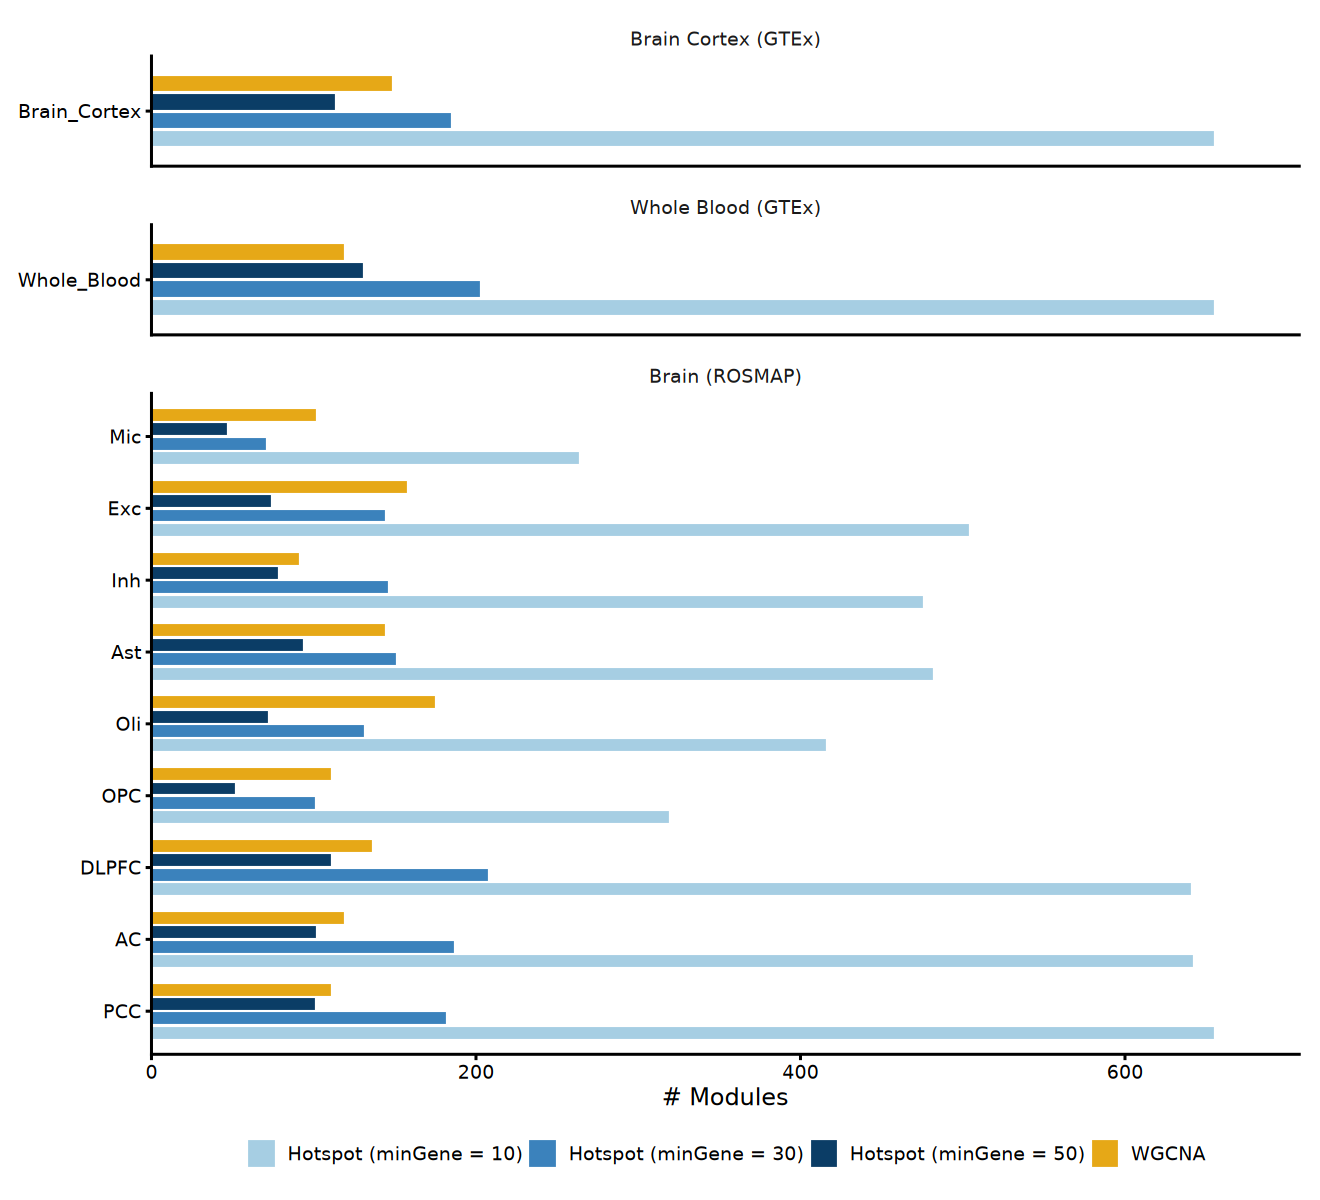

In [2]:
fill_levels <- c("Hotspot (minGene = 10)", "Hotspot (minGene = 30)", "Hotspot (minGene = 50)", "WGCNA")
fill_colors <- setNames(c("#A6CEE3", "#3B82BC", "#0B3D66", "#E6A817"), fill_levels)
ctx_levels <- c("Brain_Cortex", "Whole_Blood", "Mic", "Exc", "Inh", "Ast", "Oli", "OPC", "DLPFC", "AC", "PCC")
dat$context <- factor(dat$context, levels = rev(ctx_levels))
dat$group <- factor(dat$group, levels = fill_levels)
dat$panel <- ifelse(dat$cohort == "ROSMAP", "Brain (ROSMAP)",
                    ifelse(dat$context == "Brain_Cortex", "Brain Cortex (GTEx)", "Whole Blood (GTEx)"))

make_panel <- function(d, show_x = TRUE) {
  p <- ggplot(d, aes(x = context, y = n_modules, fill = group)) +
    geom_col(width = 0.8, position = position_dodge2(width = 0.8, padding = 0.1),
             colour = "white", linewidth = 0.25) +
    facet_wrap(~ panel) +
    scale_fill_manual(values = fill_colors, drop = FALSE, name = NULL) +
    scale_y_continuous(expand = expansion(mult = c(0, 0.08))) +
    labs(x = NULL, y = "# Modules") +
    coord_flip() +
    theme_classic(base_size = 14) +
    theme(strip.background = element_blank(), legend.position = "bottom")
  if (!show_x) p <- p + theme(axis.title.x = element_blank(), axis.text.x = element_blank(),
                              axis.ticks.x = element_blank())
  p
}
p <- (make_panel(dat[dat$panel == "Brain Cortex (GTEx)", ], FALSE) /
      make_panel(dat[dat$panel == "Whole Blood (GTEx)", ], FALSE) /
      make_panel(dat[dat$panel == "Brain (ROSMAP)", ])) +
  plot_layout(heights = c(0.5, 0.5, 3), guides = "collect") &
  theme(legend.position = "bottom")

options(repr.plot.width = 11, repr.plot.height = 10)
p